## 这部分是指定类型的频次统计

## 1 词频统计

## 统计文本中，指定人名的次数，步骤：
+ 打开人名的文本
+ 对人名进行列表化处理
+ 打开文本
+ 采用文本跟人名匹配的方式，进行人名统计（注：没有采用采用分词的方式）
+ 用字典存储：人名-频次
+ 画图展示

In [1]:
# 文件的打开与关闭

In [2]:
f_name = open('name.txt',encoding = 'GB18030') #使用mac的小伙伴，需要耐心调试下编码GB18030

In [3]:
#f_name = open('name.txt')

In [4]:
data_name = f_name.read()

In [5]:
data_name[:70]

'諸葛亮|關羽|劉備|曹操|孫權|關羽|張飛|呂布|周瑜|趙雲|龐統|司馬懿|黃忠|馬超'

In [6]:
print(data_name[:50])

諸葛亮|關羽|劉備|曹操|孫權|關羽|張飛|呂布|周瑜|趙雲|龐統|司馬懿|黃忠|馬超


In [7]:
f_name.close()

In [8]:
# 将文本转化为列表

In [9]:
names = data_name.split('|') # split一下names就是列表

In [10]:
print(names)

['諸葛亮', '關羽', '劉備', '曹操', '孫權', '關羽', '張飛', '呂布', '周瑜', '趙雲', '龐統', '司馬懿', '黃忠', '馬超']


In [11]:
names

['諸葛亮',
 '關羽',
 '劉備',
 '曹操',
 '孫權',
 '關羽',
 '張飛',
 '呂布',
 '周瑜',
 '趙雲',
 '龐統',
 '司馬懿',
 '黃忠',
 '馬超']

In [12]:
# 学习一种新的数据结构，字典

In [13]:
name_dict = {}

In [14]:
f_txt = open('sanguo.txt',encoding = 'GB18030')

In [15]:
data_txt = f_txt.read()

In [16]:
f_txt.close()

In [17]:
print(data_txt[:100])

《三国演义》（全）

（明）羅貫中著

  
第一回
宴桃園豪傑三結義斬黃巾英雄首立功
話說天下大勢，分久必合，合久必分：周末七國分爭，並
入于秦；及秦滅之後，楚、漢分爭，又並入於漢；漢朝自高祖
斬白


In [18]:
# 用count函数统计文本中的词汇

## 你没有发现下面的代码很神奇吗？data_txt点count一下，就可以统计词！实际上是字符串匹配的过程！

In [19]:
for name in names:
    name_dict[name]=data_txt.count(name)

In [20]:
name_dict

{'諸葛亮': 149,
 '關羽': 8,
 '劉備': 291,
 '曹操': 907,
 '孫權': 315,
 '張飛': 347,
 '呂布': 332,
 '周瑜': 235,
 '趙雲': 301,
 '龐統': 80,
 '司馬懿': 272,
 '黃忠': 179,
 '馬超': 212}

In [21]:
# 定义  画图 函数

In [22]:
def make_chinese_plot_ready():
    from matplotlib import rcParams
    # 原代码写的是 'Heiti TC'，那是 macOS 自带字体，Windows 上不存在，
    # 直接跑中文会显示成一排方框。这里改成 Windows 自带字体，并按优先级回退。
    rcParams['font.family'] = ['Microsoft YaHei', 'SimHei', 'SimSun']
    rcParams['axes.unicode_minus'] = False  # 让负号正常显示，不被当成特殊字符

In [23]:
# 定义 画图 函数

In [24]:
def draw_dict(mydict, figsize=(8, 5)):
    import pandas as pd
    import matplotlib.pyplot as plt
    make_chinese_plot_ready()
    df = pd.DataFrame(list(mydict.items()), columns=['name', 'times'])
    df.set_index('name')['times'].sort_values(ascending=False).plot(kind='bar', figsize=figsize)  # 做好排序
    plt.tight_layout() 

In [25]:
 # %pylab inline

In [26]:
%matplotlib inline

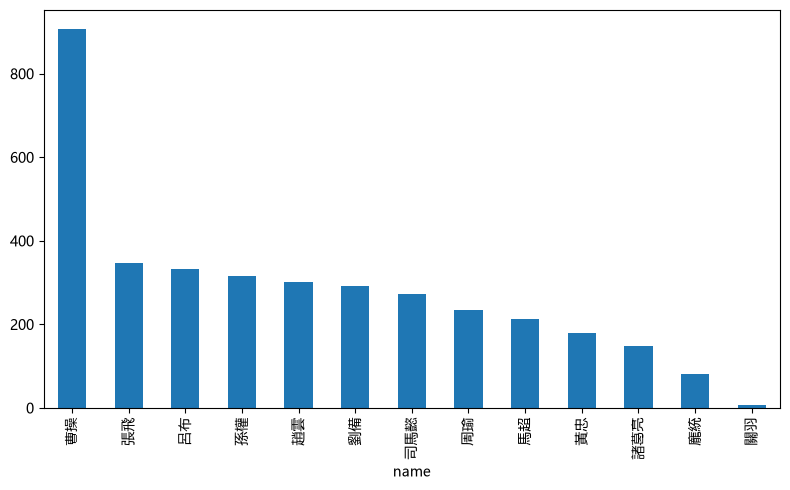

In [27]:
draw_dict(name_dict)

In [28]:
# 把统计结果按次数从高到低打印出来，便于核对图上的数值
# 注意：name.txt 里"關羽"被写了两次（共 14 个条目，去重后 13 个），
# 用字典存储时后一次会覆盖前一次，所以统计结果不受影响。
print(f"{'人名':<8}{'出现次数':>8}")
print('-' * 20)
for name, cnt in sorted(name_dict.items(), key=lambda kv: kv[1], reverse=True):
    print(f'{name:<8}{cnt:>8}')
print()
print(f'人名条目 {len(names)} 个，去重后 {len(name_dict)} 个')

人名          出现次数
--------------------
曹操           907
張飛           347
呂布           332
孫權           315
趙雲           301
劉備           291
司馬懿          272
周瑜           235
馬超           212
黃忠           179
諸葛亮          149
龐統            80
關羽             8

人名条目 14 个，去重后 13 个


## 2 统计武器

### 统计武器的步骤
+ 打开武器文本
+ 对文本进行处理，包括：去掉换行符，去掉空格，变成列表
+ 打开文本
+ 统计武器（采用文本与武器的字符进行匹配的方式，统计的。没有分词）
+ 用字典存储结果：武器-频次
+ 展示

In [29]:
f_weapon = open('weapon.txt',encoding = 'utf-8')

In [30]:
data_weapon = f_weapon.read()

In [31]:
print(data_weapon[:100])

青龍偃月刀

丈八點鋼矛

鐵脊蛇矛

涯角槍

諸葛槍

方天畫戟

長柄鐵錘

鐵蒺藜骨朵

大斧

蘸金斧

三尖刀

截頭大刀

馬岱寶刀

古錠刀

衠鋼槊

丈八長標

王雙大刀

呂虔刀


In [32]:
weapons_origin = data_weapon.split('\n')

In [33]:
print(weapons_origin[:40])

['青龍偃月刀', '', '丈八點鋼矛', '', '鐵脊蛇矛', '', '涯角槍', '', '諸葛槍', '', '方天畫戟', '', '長柄鐵錘', '', '鐵蒺藜骨朵', '', '大斧', '', '蘸金斧', '', '三尖刀', '', '截頭大刀', '', '馬岱寶刀', '', '古錠刀', '', '衠鋼槊', '', '丈八長標', '', '王雙大刀', '', '呂虔刀', '', '龍泉劍', '', '倚天劍', '']


In [34]:
weapons = []

In [35]:
for weapon in weapons_origin:
    if weapon != '':
        weapons.append(weapon)

In [36]:
weapons[:500]

['青龍偃月刀',
 '丈八點鋼矛',
 '鐵脊蛇矛',
 '涯角槍',
 '諸葛槍',
 '方天畫戟',
 '長柄鐵錘',
 '鐵蒺藜骨朵',
 '大斧',
 '蘸金斧',
 '三尖刀',
 '截頭大刀',
 '馬岱寶刀',
 '古錠刀',
 '衠鋼槊',
 '丈八長標',
 '王雙大刀',
 '呂虔刀',
 '龍泉劍',
 '倚天劍',
 '青釭',
 '七寶刀',
 '雙股劍',
 '松紋廂寶劍',
 '孟德劍',
 '思召劍',
 '飛景三劍',
 '文士劍',
 '蜀八劍',
 '鎮山劍',
 '吳六劍',
 '皇帝吳王劍',
 '日月刀',
 '百辟寶刀',
 '龍鱗刀',
 '百辟匕首二',
 '鐵鞭',
 '鋼鞭',
 '四楞鐵簡',
 '雙鐵戟',
 '諸葛連弩',
 '寶雕弓',
 '鵲畫弓',
 '虎筋弦弓',
 '兩石力之弓',
 '手戟',
 '短戟',
 '飛石',
 '流星錘',
 '銅撾']

In [37]:
weapon_dict = {}

## 同样是字符串匹配

In [38]:
for weapon in weapons:
    weapon_dict[weapon] = data_txt.count(weapon)

In [39]:
weapon_dict

{'青龍偃月刀': 2,
 '丈八點鋼矛': 4,
 '鐵脊蛇矛': 1,
 '涯角槍': 0,
 '諸葛槍': 0,
 '方天畫戟': 2,
 '長柄鐵錘': 0,
 '鐵蒺藜骨朵': 0,
 '大斧': 14,
 '蘸金斧': 1,
 '三尖刀': 1,
 '截頭大刀': 1,
 '馬岱寶刀': 0,
 '古錠刀': 1,
 '衠鋼槊': 0,
 '丈八長標': 1,
 '王雙大刀': 0,
 '呂虔刀': 0,
 '龍泉劍': 0,
 '倚天劍': 1,
 '青釭': 0,
 '七寶刀': 1,
 '雙股劍': 3,
 '松紋廂寶劍': 0,
 '孟德劍': 0,
 '思召劍': 0,
 '飛景三劍': 0,
 '文士劍': 0,
 '蜀八劍': 0,
 '鎮山劍': 0,
 '吳六劍': 0,
 '皇帝吳王劍': 0,
 '日月刀': 1,
 '百辟寶刀': 0,
 '龍鱗刀': 0,
 '百辟匕首二': 0,
 '鐵鞭': 1,
 '鋼鞭': 2,
 '四楞鐵簡': 1,
 '雙鐵戟': 2,
 '諸葛連弩': 0,
 '寶雕弓': 3,
 '鵲畫弓': 1,
 '虎筋弦弓': 0,
 '兩石力之弓': 0,
 '手戟': 0,
 '短戟': 2,
 '飛石': 2,
 '流星錘': 3,
 '銅撾': 0}

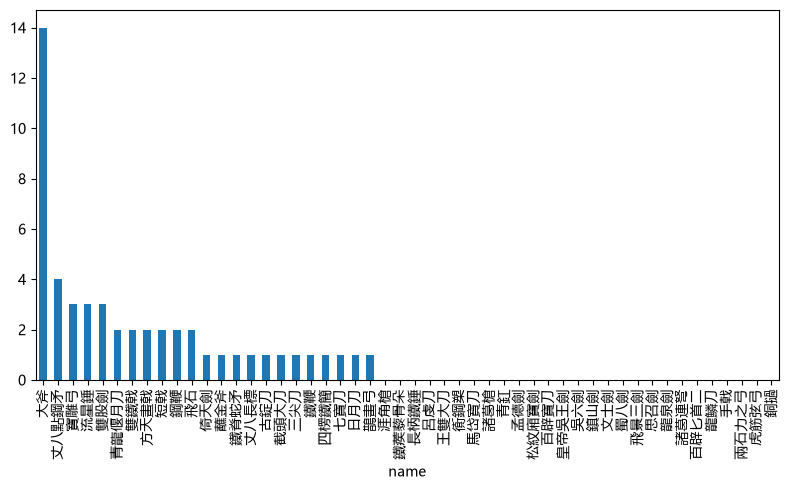

In [40]:
draw_dict(weapon_dict)

In [41]:
# 以上出的图看上去不清晰，如何保存清晰的图？
import matplotlib.pyplot as plt
plt.savefig('weapon000.png')

<Figure size 640x480 with 0 Axes>

## 作业
+ 请完成以上两个python的代码
+ 请把以上文本替换成功文件夹中的《科学家博物馆-黄旭华传记序言.txt》，完成该文档中的全文词频统计，以及指定词汇统计，如统计"黄旭华"、"核潜艇"出现的次数。

---

## 作业解答

作业要求：把上面的方法迁移到《科学家博物馆-黄旭华传记序言.txt》。

三国文本统计的是**人名**和**武器**，黄旭华文本里对应的是**人物**和**专业术语**。下面用完全相同的 `str.count` 方法做迁移验证。

《黄旭华传记序言》指定词汇统计：
  黄旭华             59 次
  核潜艇             32 次
  采集              29 次
  院士              13 次
  国立交通大学           3 次
  总设计师             2 次


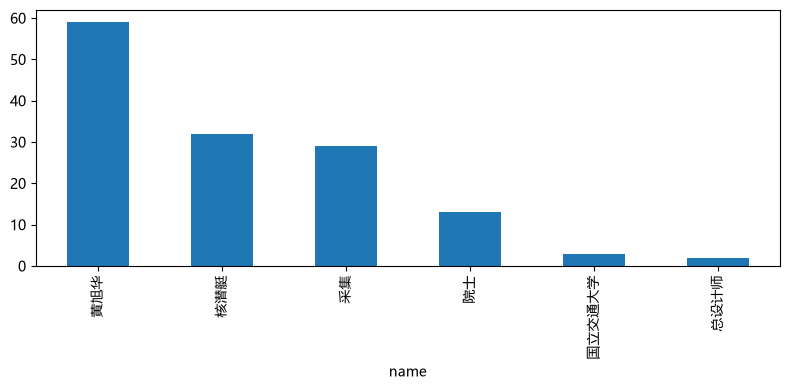

In [42]:
# 迁移验证：用同一套字符串匹配方法，统计黄旭华文本中的人物与专业术语
f2 = open('科学家博物馆-黄旭华传记序言.txt', encoding='utf-8')
data2 = f2.read()
f2.close()

terms = ['黄旭华', '核潜艇', '国立交通大学', '院士', '总设计师', '采集']
hx_dict = {t: data2.count(t) for t in terms}

print('《黄旭华传记序言》指定词汇统计：')
for t, c in sorted(hx_dict.items(), key=lambda kv: kv[1], reverse=True):
    print(f'  {t:<14}{c:>4} 次')

make_chinese_plot_ready()
draw_dict(hx_dict, figsize=(8, 4))

### 迁移之后发现的四个问题

**1. 零命中说明"词表必须先和文本对齐"。**
武器统计里 50 个兵器名有 **27 个一次都没出现**，命中率只有 46%。这不是程序写错，而是 `weapon.txt` 收录的兵器名远比正文实际用词宽——大量生僻兵器在《三国演义》里根本没被提到。**做词频统计前必须先检查词表与文本的覆盖率**，否则图表里会出现一堆毫无意义的零。

**2. 换文本就要换词表，但方法不变。**
三国统计人名，黄旭华文本统计"核潜艇""国立交通大学"这类专业术语。**代码几乎一模一样（都是 `str.count`），变的只是领域词表**——这就是词频统计最朴素的用法：先确定你关心的词，再去数它出现多少次。

**3. 文本量决定结论的稳定性。**
《黄旭华传记序言》只有 4,030 字，"黄旭华"出现 59 次看似很高；但《三国演义》全文 62 万字，"曹操"出现 907 次。**短文本里任何一处措辞变化都会让排名剧烈跳动**，长文本才谈得上稳定规律。

**4. 字符匹配不辨语义。**
"院士"在文中出现 13 次，但光看数字无法知道说的是"当选院士"还是"院士精神"。这正是第 1 讲结尾提出的问题——**词频只回答"多少次"，不回答"怎么样"**。要回答后者，必须走到关系抽取和语义分析，那是后面几讲的内容。